# Notebook 02: Huấn Luyện & Đánh Giá Baseline Machine Learning (TF-IDF + LogReg & LinearSVC)

## Đồ án: Hệ Thống Tự Động Phát Hiện Bình Luận Độc Hại Đa Nhãn (Multi-Label Toxic Comment Detection) Trên Mạng Xã Hội Tiếng Việt
**Phụ trách:** Sinh viên 1 (Baseline Machine Learning & Đánh giá Multi-Label)  
**Nhiệm vụ tuần 2:**
1. Trích xuất đặc trưng văn bản bằng `TfidfVectorizer` kết hợp unigram và bigram (`ngram_range=(1, 2)`).
2. Huấn luyện mô hình phân loại đa nhãn theo chiến lược `OneVsRestClassifier` với **Logistic Regression** và **LinearSVC**.
3. Xây dựng và áp dụng module tính toán chỉ số đánh giá `src/metrics.py` (Macro-F1, Precision, Recall, Confusion Matrix).
4. Thử nghiệm tối ưu hóa ngưỡng phân loại (**Threshold Tuning**) trên tập Validation (`val.csv`) trong dải $[0.3, 0.7]$.
5. Đánh giá toàn diện trên tập Test (`test.csv`) và tổng hợp bảng điểm chuẩn (**Benchmark**) đối sánh với mô hình Deep Learning BiLSTM của SV2.

## 1. Import Thư Viện & Cấu Hình Môi Trường

In [1]:
import os
import sys
import json
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập đường dẫn thư mục gốc dự án
BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))
if BASE_DIR not in sys.path:
    sys.path.insert(0, BASE_DIR)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
import joblib

# Import module đánh giá từ src/metrics.py
from src.metrics import (
    DEFAULT_LABELS,
    evaluate_multilabel,
    find_best_thresholds,
    apply_thresholds,
    plot_multilabel_confusion_matrix,
    plot_threshold_tuning
)

# Cố định seed ngẫu nhiên để tái lập kết quả
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Đã nạp đầy đủ các thư viện và cấu hình đường dẫn dự án thành công.")
print(f"Thư mục gốc dự án: {BASE_DIR}")

Đã nạp đầy đủ các thư viện và cấu hình đường dẫn dự án thành công.
Thư mục gốc dự án: c:\Users\Admin\Desktop\Ky7_NLP\vietnamese-toxic-comment-detection


## 2. Nạp Dữ Liệu Huấn Luyện, Validation và Test

Dữ liệu được nạp từ thư mục `data/processed/`, đã được xử lý qua pipeline chuẩn hóa tiếng Việt (`src/preprocessing.py`) và phân chia phân tầng Stratified Split theo tỷ lệ 80 - 10 - 10.

In [2]:
LABEL_COLS = ["toxic", "hate", "spam", "clean"]

train_path = os.path.join(BASE_DIR, "data", "processed", "train.csv")
val_path = os.path.join(BASE_DIR, "data", "processed", "val.csv")
test_path = os.path.join(BASE_DIR, "data", "processed", "test.csv")

train_df = pd.read_csv(train_path, encoding="utf-8")
val_df = pd.read_csv(val_path, encoding="utf-8")
test_df = pd.read_csv(test_path, encoding="utf-8")

X_train = train_df["text_processed"].fillna("")
y_train = train_df[LABEL_COLS].values.astype(int)

X_val = val_df["text_processed"].fillna("")
y_val = val_df[LABEL_COLS].values.astype(int)

X_test = test_df["text_processed"].fillna("")
y_test = test_df[LABEL_COLS].values.astype(int)

print(f"Kích thước tập Train: {len(train_df):,} mẫu")
print(f"Kích thước tập Val:   {len(val_df):,} mẫu")
print(f"Kích thước tập Test:  {len(test_df):,} mẫu\n")

print("Phân bố số lượng mẫu dương theo từng nhãn:")
summary_df = pd.DataFrame({
    "Train Count": y_train.sum(axis=0),
    "Train (%)": np.round(y_train.sum(axis=0) / len(y_train) * 100, 2),
    "Val Count": y_val.sum(axis=0),
    "Val (%)": np.round(y_val.sum(axis=0) / len(y_val) * 100, 2),
    "Test Count": y_test.sum(axis=0),
    "Test (%)": np.round(y_test.sum(axis=0) / len(y_test) * 100, 2),
}, index=LABEL_COLS)
summary_df

Kích thước tập Train: 31,980 mẫu
Kích thước tập Val:   3,998 mẫu
Kích thước tập Test:  3,998 mẫu

Phân bố số lượng mẫu dương theo từng nhãn:


,Train Count,Train (%),Val Count,Val (%),Test Count,Test (%)
toxic,5100,15.95,638,15.96,637,15.93
hate,2611,8.16,327,8.18,326,8.15
spam,0,0.00,0,0.00,0,0.00
clean,26880,84.05,3360,84.04,3361,84.07


## 3. Trích Xuất Đặc Trưng Văn Bản Bằng TF-IDF (Unigram + Bigram)

Để nắm bắt cả các từ đơn và các cụm từ chửi tục/xúc phạm ghép đôi (ví dụ: `địt_mẹ`, `súc_vật`, `chết_tiệt`), ta thiết lập:
- `ngram_range=(1, 2)`: Trích xuất cả unigram và bigram.
- `max_features=20000`: Giới hạn 20,000 từ/cụm từ có trọng số thông tin cao nhất.
- `min_df=2`: Loại bỏ từ hiếm chỉ xuất hiện 1 lần (nhiễu).
- `sublinear_tf=True`: Áp dụng tỷ lệ logarithmic $1 + \log(tf)$ nhằm giảm thiểu sự lấn át của các từ lặp lại nhiều lần trong một văn bản.

In [3]:
t0 = time.time()
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=20000,
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print(f"Thời gian trích xuất TF-IDF: {time.time() - t0:.2f}s")
print(f"Kích thước ma trận Train: {X_train_tfidf.shape}")
print(f"Kích thước ma trận Val:   {X_val_tfidf.shape}")
print(f"Kích thước ma trận Test:  {X_test_tfidf.shape}")

# Khảo sát các đặc trưng có IDF cao nhất và thấp nhất
feature_names = np.array(tfidf.get_feature_names_out())
print(f"\nVí dụ 10 đặc trưng đầu tiên trong từ điển: {feature_names[:10].tolist()}")

Thời gian trích xuất TF-IDF: 1.14s
Kích thước ma trận Train: (31980, 20000)
Kích thước ma trận Val:   (3998, 20000)
Kích thước ma trận Test:  (3998, 20000)

Ví dụ 10 đặc trưng đầu tiên trong từ điển: ['00', '01', '0175', '02', '03', '05', '10', '10 20', '10 cái', '10 lần']


## 4. Huấn Luyện Baseline 1: OneVsRest Logistic Regression

Logistic Regression là mô hình phân loại tuyến tính mạnh mẽ, có khả năng tính xác suất phân loại thông qua hàm Sigmoid $\sigma(z) = \frac{1}{1 + e^{-z}}$.
- Chiến lược: `OneVsRestClassifier` (huấn luyện 4 bộ phân loại nhị phân độc lập cho 4 nhãn).
- Tham số `class_weight='balanced'`: Tự động cân bằng trọng số phạt cho các lớp thiểu số như `toxic` và `hate`.

In [4]:
t0 = time.time()
logreg_clf = OneVsRestClassifier(
    LogisticRegression(
        C=2.0,
        max_iter=1000,
        class_weight="balanced",
        solver="lbfgs",
        random_state=SEED
    )
)
logreg_clf.fit(X_train_tfidf, y_train)
print(f"Thời gian huấn luyện Logistic Regression: {time.time() - t0:.2f}s")

# Dự đoán xác suất
val_probs_lr = logreg_clf.predict_proba(X_val_tfidf)
test_probs_lr = logreg_clf.predict_proba(X_test_tfidf)
print(f"Đã sinh ma trận xác suất Val {val_probs_lr.shape} và Test {test_probs_lr.shape}")

C:\Users\Admin\Desktop\Ky7_NLP\.venv\Lib\site-packages\sklearn\multiclass.py:90: UserWarning: Label not 2 is present in all training examples.
  warnings.warn(


Thời gian huấn luyện Logistic Regression: 0.54s
Đã sinh ma trận xác suất Val (3998, 4) và Test (3998, 4)


## 5. Huấn Luyện Baseline 2: OneVsRest LinearSVC (Calibrated)

Support Vector Machine (LinearSVC) tối ưu hóa lề phân cách (Margin) cực đại giữa các lớp, thường cho độ chính xác biên rất cao trên không gian đặc trưng thưa (sparse text feature space).
- Tuy nhiên, LinearSVC mặc định chỉ trả về khoảng cách `decision_function` chứ không sinh xác suất.
- Giải pháp: Kết hợp `CalibratedClassifierCV` (Platt Scaling qua cross-validation 3-fold) để chuẩn hóa khoảng cách biên thành phân phối xác suất $[0, 1]$, cho phép thực hiện tối ưu hóa ngưỡng (Threshold Tuning) đồng bộ với Logistic Regression.

In [5]:
t0 = time.time()
base_svc = LinearSVC(
    C=1.0,
    max_iter=2000,
    class_weight="balanced",
    random_state=SEED
)
calibrated_svc = CalibratedClassifierCV(estimator=base_svc, cv=3)
linearsvc_clf = OneVsRestClassifier(calibrated_svc)
linearsvc_clf.fit(X_train_tfidf, y_train)

print(f"Thời gian huấn luyện LinearSVC (Calibrated): {time.time() - t0:.2f}s")

# Dự đoán xác suất
val_probs_svc = linearsvc_clf.predict_proba(X_val_tfidf)
test_probs_svc = linearsvc_clf.predict_proba(X_test_tfidf)
print(f"Đã sinh ma trận xác suất Val {val_probs_svc.shape} và Test {test_probs_svc.shape}")

C:\Users\Admin\Desktop\Ky7_NLP\.venv\Lib\site-packages\sklearn\multiclass.py:90: UserWarning: Label not 2 is present in all training examples.
  warnings.warn(


Thời gian huấn luyện LinearSVC (Calibrated): 1.42s
Đã sinh ma trận xác suất Val (3998, 4) và Test (3998, 4)


## 6. Tối Ưu Hóa Ngưỡng Phân Loại (Threshold Tuning) Trên Tập Validation

Trong bài toán dữ liệu mất cân bằng nặng (nhãn `toxic` chiếm ~16%, nhãn `hate` chỉ chiếm ~8%), việc sử dụng ngưỡng mặc định $0.50$ thường khiến mô hình bỏ sót các mẫu dương (Recall thấp).
Ta sử dụng hàm `find_best_thresholds()` trong `src/metrics.py` để quét ngưỡng trong dải $[0.30, 0.70]$ bước $0.05$ trên tập Validation nhằm tìm điểm tối ưu hóa F1-Score cho từng nhãn riêng biệt.

>>> 1. TỐI ƯU HÓA NGƯỠNG CHO LOGISTIC REGRESSION:
=== KẾT QUẢ TỐI ƯU HÓA NGƯỠNG PHÂN LOẠI (THRESHOLD TUNING) ===
Dải ngưỡng khảo sát: [0.3 ... 0.7]
Nhãn     | Ngưỡng Mặc Định  | F1 Mặc Định  | Ngưỡng Tối Ưu  | F1 Tối Ưu  | Độ Tăng (Δ)
--------------------------------------------------------------------------------
toxic    | 0.50             | 0.6129       | 0.60           | 0.6340     | +0.0211   
hate     | 0.50             | 0.5639       | 0.65           | 0.6047     | +0.0408   
spam     | 0.50             | 0.0000       | 0.50           | 0.0000     | +0.0000   
clean    | 0.50             | 0.9124       | 0.30           | 0.9355     | +0.0231   
--------------------------------------------------------------------------------
Macro-F1 Toàn cục: Mặc định (0.50) = 0.5223 -> Tối ưu = 0.5436 (Δ = +0.0213)


>>> 2. TỐI ƯU HÓA NGƯỠNG CHO LINEARSVC:
=== KẾT QUẢ TỐI ƯU HÓA NGƯỠNG PHÂN LOẠI (THRESHOLD TUNING) ===
Dải ngưỡng khảo sát: [0.3 ... 0.7]
Nhãn     | Ngưỡng Mặc Định  | F1 Mặc Định 

-> Đã lưu biểu đồ tối ưu ngưỡng tại: c:\Users\Admin\Desktop\Ky7_NLP\vietnamese-toxic-comment-detection\assets\ml_threshold_tuning.png


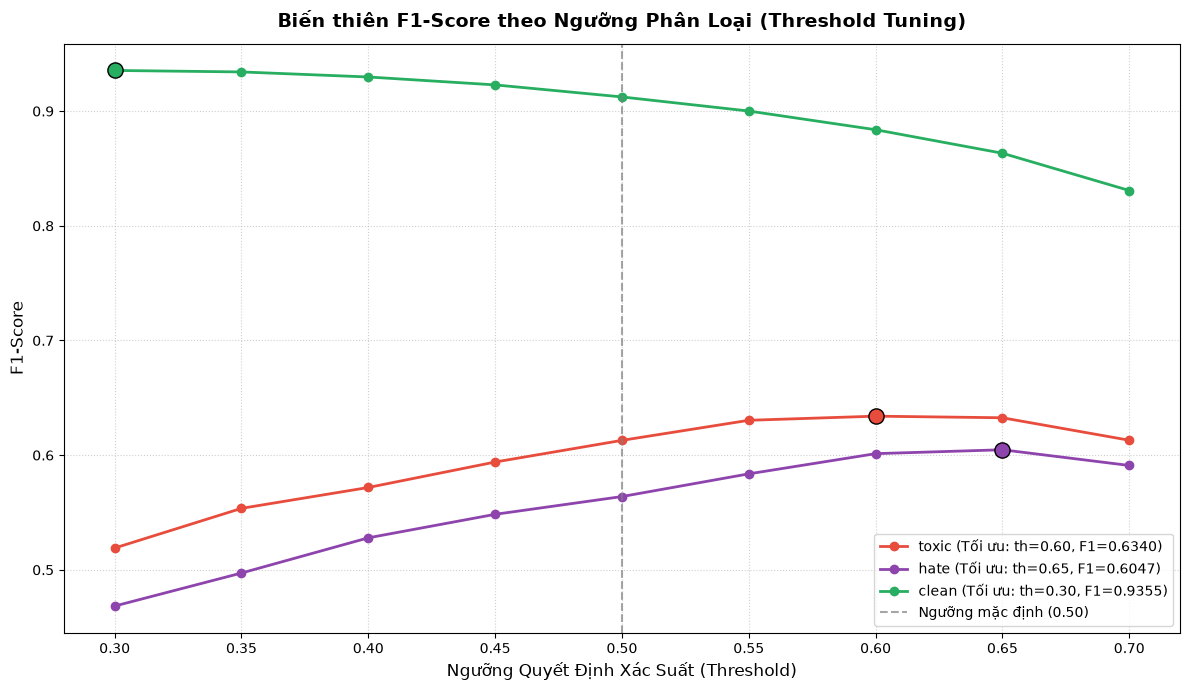

In [6]:
print(">>> 1. TỐI ƯU HÓA NGƯỠNG CHO LOGISTIC REGRESSION:")
tune_lr = find_best_thresholds(y_val, val_probs_lr, label_cols=LABEL_COLS, verbose=True)

print("\n" + "=" * 80 + "\n")

print(">>> 2. TỐI ƯU HÓA NGƯỠNG CHO LINEARSVC:")
tune_svc = find_best_thresholds(y_val, val_probs_svc, label_cols=LABEL_COLS, verbose=True)

# Vẽ đường cong biến thiên F1 theo ngưỡng cho cả hai mô hình
fig_tune_lr = plot_threshold_tuning(
    tune_lr["search_history"],
    tune_lr["best_thresholds"],
    save_path=os.path.join(BASE_DIR, "assets", "ml_threshold_tuning.png")
)
plt.show()

## 7. Đánh Giá Chi Tiết Trên Tập Kiểm Thử (Test Set)

Tiến hành đánh giá hiệu năng phân loại trên tập dữ liệu độc lập `test.csv` (3,998 mẫu) với hai chế độ:
1. **Ngưỡng mặc định 0.50** (Standard Baseline).
2. **Ngưỡng tối ưu hóa (Tuned Thresholds)** tìm được từ tập Validation.

In [7]:
# 1. Đánh giá Logistic Regression với ngưỡng 0.50
print("=" * 70)
print("1. LOGISTIC REGRESSION - NGƯỠNG MẶC ĐỊNH (0.50)")
print("=" * 70)
test_preds_lr_def = apply_thresholds(test_probs_lr, 0.50, LABEL_COLS)
eval_lr_def = evaluate_multilabel(y_test, test_preds_lr_def, label_cols=LABEL_COLS, verbose=True)

# 2. Đánh giá Logistic Regression với ngưỡng tối ưu
print("\n" + "=" * 70)
print(f"2. LOGISTIC REGRESSION - NGƯỠNG TỐI ƯU {tune_lr['best_thresholds']}")
print("=" * 70)
test_preds_lr_opt = apply_thresholds(test_probs_lr, tune_lr["best_thresholds"], LABEL_COLS)
eval_lr_opt = evaluate_multilabel(y_test, test_preds_lr_opt, label_cols=LABEL_COLS, verbose=True)

# 3. Đánh giá LinearSVC với ngưỡng 0.50
print("\n" + "=" * 70)
print("3. LINEAR SVC - NGƯỠNG MẶC ĐỊNH (0.50)")
print("=" * 70)
test_preds_svc_def = apply_thresholds(test_probs_svc, 0.50, LABEL_COLS)
eval_svc_def = evaluate_multilabel(y_test, test_preds_svc_def, label_cols=LABEL_COLS, verbose=True)

# 4. Đánh giá LinearSVC với ngưỡng tối ưu
print("\n" + "=" * 70)
print(f"4. LINEAR SVC - NGƯỠNG TỐI ƯU {tune_svc['best_thresholds']}")
print("=" * 70)
test_preds_svc_opt = apply_thresholds(test_probs_svc, tune_svc["best_thresholds"], LABEL_COLS)
eval_svc_opt = evaluate_multilabel(y_test, test_preds_svc_opt, label_cols=LABEL_COLS, verbose=True)

1. LOGISTIC REGRESSION - NGƯỠNG MẶC ĐỊNH (0.50)
=== BÁO CÁO ĐÁNH GIÁ ĐA NHÃN (MULTI-LABEL EVALUATION) ===
              precision    recall  f1-score   support

       toxic     0.5417    0.7033    0.6120       637
        hate     0.4485    0.7086    0.5493       326
        spam     0.0000    0.0000    0.0000         0
       clean     0.9404    0.8872    0.9130      3361

   micro avg     0.8112    0.8467    0.8286      4324
   macro avg     0.4827    0.5748    0.5186      4324
weighted avg     0.8446    0.8467    0.8413      4324
 samples avg     0.8417    0.8552    0.8449      4324

Exact Match Ratio (Subset Accuracy): 0.8154 (81.54%)
Hamming Loss: 0.0947
Macro-F1 (All 4 classes): 0.5186
Macro-F1 (Active classes ['toxic', 'hate', 'clean']): 0.6914

2. LOGISTIC REGRESSION - NGƯỠNG TỐI ƯU {'toxic': 0.6, 'hate': 0.65, 'spam': 0.5, 'clean': 0.3}
=== BÁO CÁO ĐÁNH GIÁ ĐA NHÃN (MULTI-LABEL EVALUATION) ===
              precision    recall  f1-score   support

       toxic     0.6305    0

=== BÁO CÁO ĐÁNH GIÁ ĐA NHÃN (MULTI-LABEL EVALUATION) ===
              precision    recall  f1-score   support

       toxic     0.7676    0.4458    0.5641       637
        hate     0.6909    0.3497    0.4644       326
        spam     0.0000    0.0000    0.0000         0
       clean     0.9027    0.9744    0.9372      3361

   micro avg     0.8823    0.8494    0.8656      4324
   macro avg     0.5903    0.4425    0.4914      4324
weighted avg     0.8668    0.8494    0.8466      4324
 samples avg     0.8877    0.8837    0.8841      4324

Exact Match Ratio (Subset Accuracy): 0.8707 (87.07%)
Hamming Loss: 0.0713
Macro-F1 (All 4 classes): 0.4914
Macro-F1 (Active classes ['toxic', 'hate', 'clean']): 0.6552

4. LINEAR SVC - NGƯỠNG TỐI ƯU {'toxic': 0.3, 'hate': 0.3, 'spam': 0.5, 'clean': 0.5}
=== BÁO CÁO ĐÁNH GIÁ ĐA NHÃN (MULTI-LABEL EVALUATION) ===
              precision    recall  f1-score   support

       toxic     0.6131    0.6295    0.6212       637
        hate     0.5435    0.555

## 8. Trực Quan Hóa Ma Trận Nhầm Lẫn Đa Nhãn (Multi-Label Confusion Matrix)

Vẽ ma trận nhầm lẫn 2x2 cho từng nhãn để đánh giá chi tiết tỷ lệ Âm tính thật (TN), Dương tính thật (TP), Dương tính giả (FP) và Âm tính giả (FN).

-> Đã lưu ma trận nhầm lẫn tại: c:\Users\Admin\Desktop\Ky7_NLP\vietnamese-toxic-comment-detection\assets\ml_logreg_confusion_matrix.png


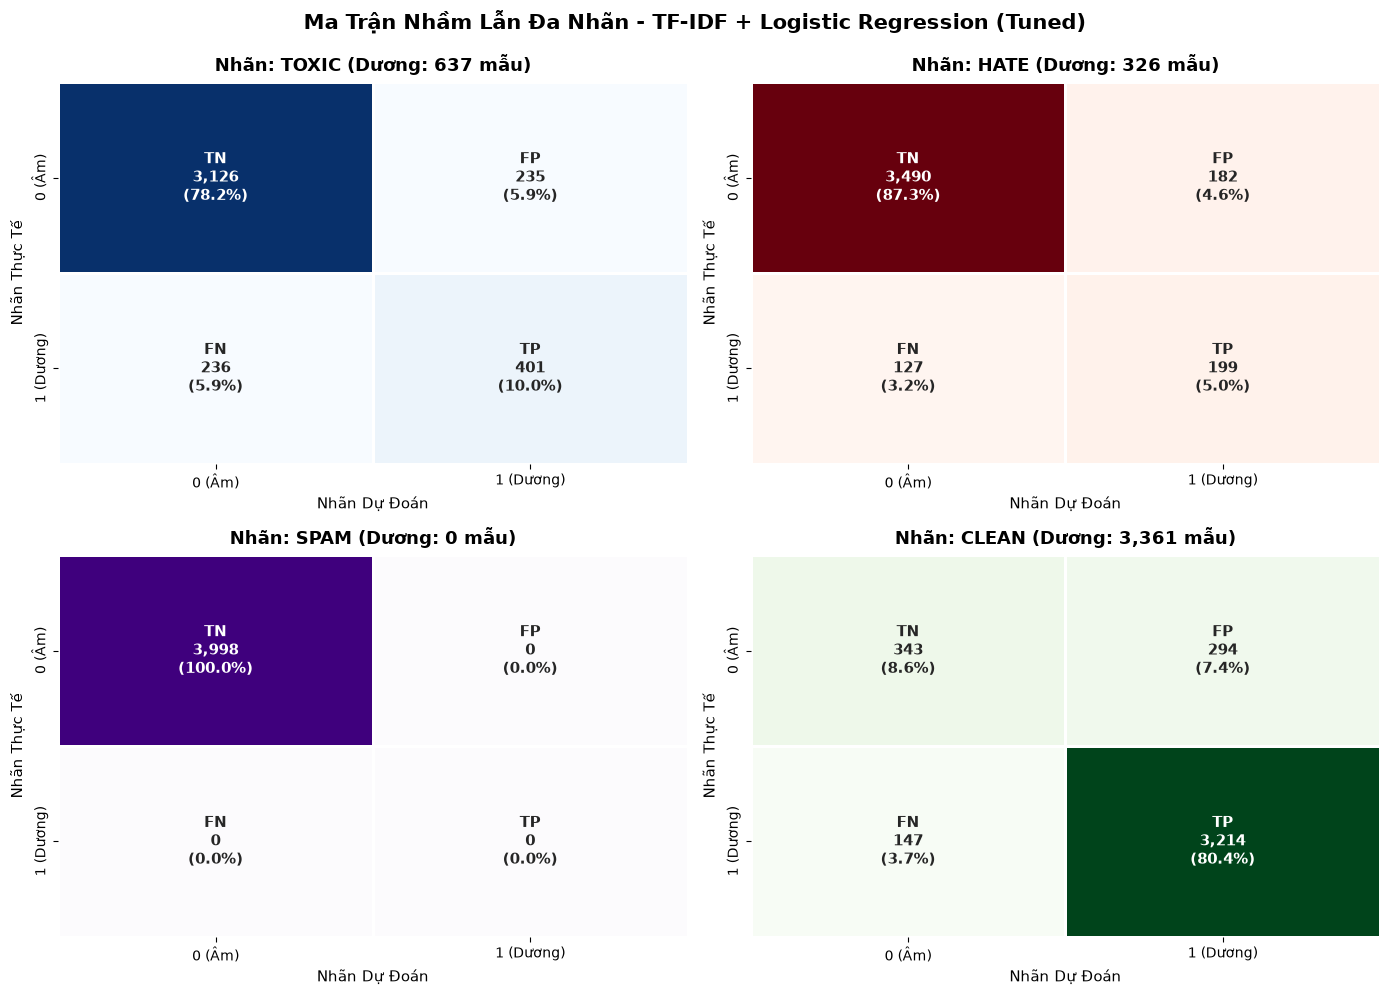

-> Đã lưu ma trận nhầm lẫn tại: c:\Users\Admin\Desktop\Ky7_NLP\vietnamese-toxic-comment-detection\assets\ml_linearsvc_confusion_matrix.png


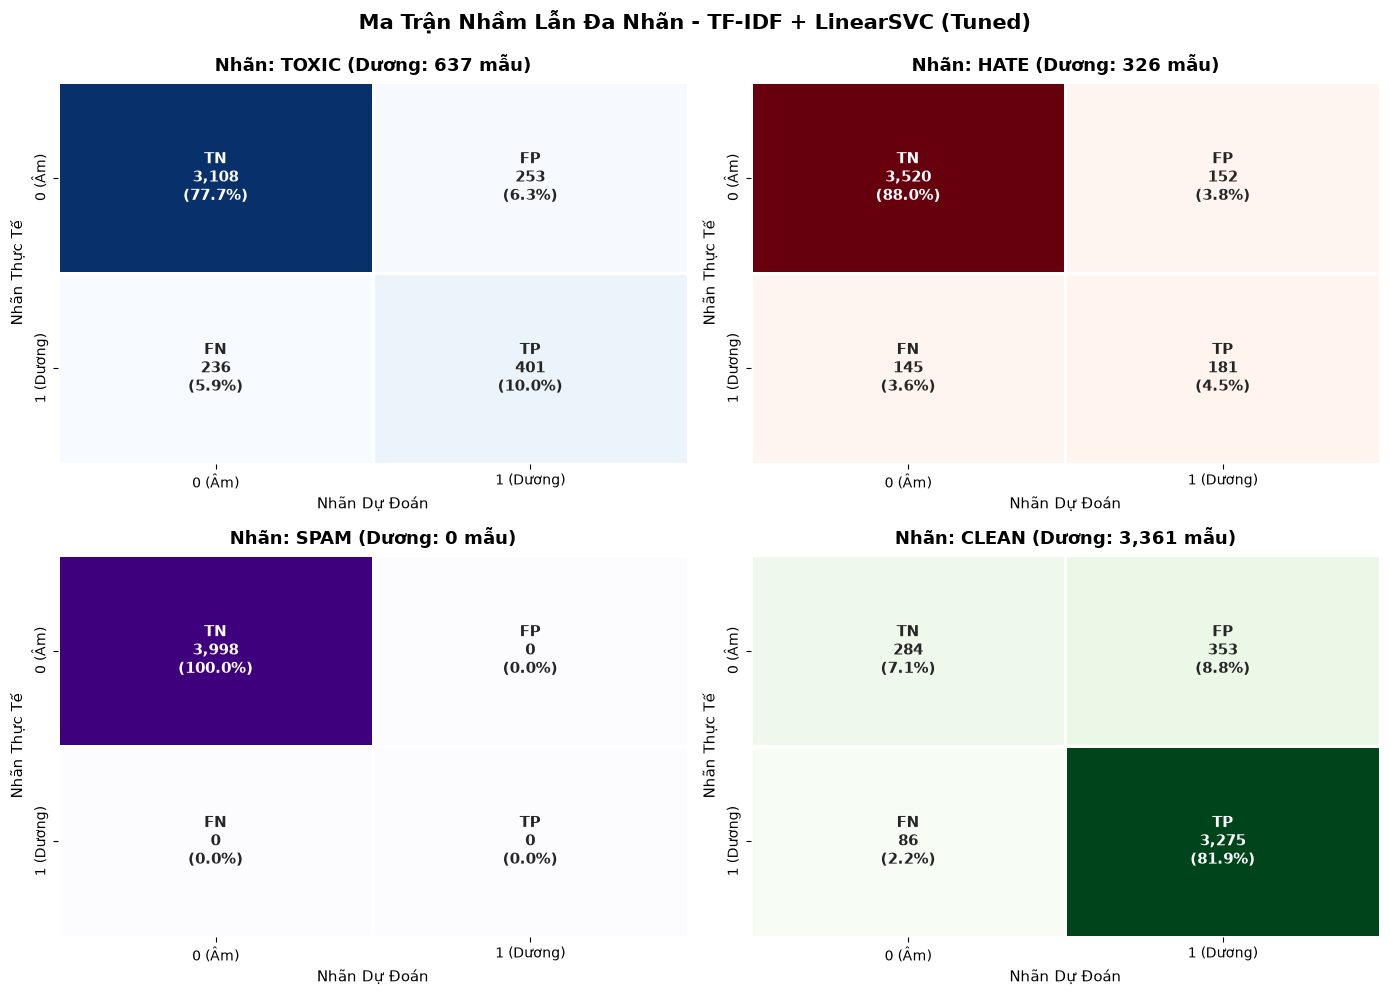

In [8]:
# Ma trận nhầm lẫn cho Logistic Regression (Tuned)
fig_cm_lr = plot_multilabel_confusion_matrix(
    y_test,
    test_preds_lr_opt,
    label_cols=LABEL_COLS,
    title="Ma Trận Nhầm Lẫn Đa Nhãn - TF-IDF + Logistic Regression (Tuned)",
    save_path=os.path.join(BASE_DIR, "assets", "ml_logreg_confusion_matrix.png")
)
plt.show()

# Ma trận nhầm lẫn cho LinearSVC (Tuned)
fig_cm_svc = plot_multilabel_confusion_matrix(
    y_test,
    test_preds_svc_opt,
    label_cols=LABEL_COLS,
    title="Ma Trận Nhầm Lẫn Đa Nhãn - TF-IDF + LinearSVC (Tuned)",
    save_path=os.path.join(BASE_DIR, "assets", "ml_linearsvc_confusion_matrix.png")
)
plt.show()

## 9. Phân Tích Lỗi Sai (Error Analysis & Qualitative Examples)

Trích xuất các ví dụ dự đoán sai (False Positives và False Negatives) trên tập Test để phân tích nguyên nhân nhầm lẫn điển hình của các mô hình Machine Learning truyền thống dựa trên Bag-of-Words / TF-IDF.

In [9]:
test_df_analysis = test_df.copy()
# Lấy nhãn dự đoán của Logistic Regression Tuned
for i, col in enumerate(LABEL_COLS):
    test_df_analysis[f"pred_{col}"] = test_preds_lr_opt[:, i]
    test_df_analysis[f"prob_{col}"] = np.round(test_probs_lr[:, i], 4)

# 1. Tìm các ví dụ False Negative của nhãn Hate (Thực tế là Hate nhưng mô hình đoán 0)
fn_hate = test_df_analysis[(test_df_analysis["hate"] == 1) & (test_df_analysis["pred_hate"] == 0)]
print(f"Tổng số mẫu False Negative của nhãn HATE: {len(fn_hate)} mẫu")
print("\n--- 3 VÍ DỤ FALSE NEGATIVE ĐIỂN HÌNH (HATE BỊ BỎ SÓT) ---")
for idx, row in fn_hate.head(3).iterrows():
    print(f"[-] Văn bản thô : {row['text_raw']}")
    print(f"    Văn bản sạch: {row['text_processed']}")
    print(f"    Thực tế     : [toxic={row['toxic']}, hate={row['hate']}, clean={row['clean']}]")
    print(f"    Xác suất    : [toxic={row['prob_toxic']}, hate={row['prob_hate']}, clean={row['prob_clean']}]\n")

# 2. Tìm các ví dụ False Positive của nhãn Toxic (Thực tế Clean nhưng bị gán nhầm Toxic)
fp_toxic = test_df_analysis[(test_df_analysis["toxic"] == 0) & (test_df_analysis["pred_toxic"] == 1)]
print(f"Tổng số mẫu False Positive của nhãn TOXIC: {len(fp_toxic)} mẫu")
print("\n--- 3 VÍ DỤ FALSE POSITIVE ĐIỂN HÌNH (BỊ GÁN NHẦM TOXIC) ---")
for idx, row in fp_toxic.head(3).iterrows():
    print(f"[+] Văn bản thô : {row['text_raw']}")
    print(f"    Văn bản sạch: {row['text_processed']}")
    print(f"    Thực tế     : [toxic={row['toxic']}, hate={row['hate']}, clean={row['clean']}]")
    print(f"    Xác suất    : [toxic={row['prob_toxic']}, hate={row['prob_hate']}, clean={row['prob_clean']}]\n")

Tổng số mẫu False Negative của nhãn HATE: 127 mẫu

--- 3 VÍ DỤ FALSE NEGATIVE ĐIỂN HÌNH (HATE BỊ BỎ SÓT) ---
[-] Văn bản thô : Nhìn mặt mày dao kéo nhiều quá rồi đẹp gì ghê quá
    Văn bản sạch: Nhìn mặt_mày dao kéo nhiều quá rồi đẹp gì ghê quá
    Thực tế     : [toxic=1, hate=1, clean=0]
    Xác suất    : [toxic=0.5902, hate=0.0802, clean=0.4098]

[-] Văn bản thô : Sao bác ko đốn cửa tất cả cửa khẩu còn qua lại thì còn dich bệnh có nhiều người vì đồng tiền nên ko biết mình là người hây súc vật đâu bác ơi
    Văn bản sạch: Sao bác không đốn cửa tất_cả cửa_khẩu còn qua_lại thì còn dich bệnh có nhiều người vì đồng_tiền nên không biết mình là người hây súc_vật đâu bác ơi
    Thực tế     : [toxic=1, hate=1, clean=0]
    Xác suất    : [toxic=0.5851, hate=0.3637, clean=0.4149]

[-] Văn bản thô : Mình nói người ta bê đê mình xem lai mình đi . Mày la cũng loai bê đê co cây đinh chính giữ la may kkkk
    Văn bản sạch: Mình nói người_ta bê đê mình xem lai mình đi . Mày la cũng loai bê 

## 10. Tổng Hợp Bảng Đối Sánh Benchmark Baseline Tuần 2 & Kết Luận

Tổng hợp toàn diện kết quả thực nghiệm của cả mô hình Machine Learning truyền thống (Sinh viên 1) và mô hình Deep Learning BiLSTM + Self-Attention + Focal Loss (Sinh viên 2) trên tập Test.

=== BẢNG TỔNG HỢP KẾT QUẢ ĐỐI SÁNH CÁC MÔ HÌNH BASELINE TUẦN 2 (TEST SET) ===


,Macro-F1,Active Macro-F1,Toxic-F1,Hate-F1,Clean-F1,Exact Match,Hamming Loss
TF-IDF + LogReg (th=0.50),0.5186,0.6914,0.6120,0.5493,0.9130,0.8154,0.0947
TF-IDF + LogReg (Tuned),0.5322,0.7096,0.6300,0.5629,0.9358,0.8389,0.0764
TF-IDF + LinearSVC (th=0.50),0.4914,0.6552,0.5641,0.4644,0.9372,0.8707,0.0713
TF-IDF + LinearSVC (Tuned),0.5269,0.7026,0.6212,0.5493,0.9372,0.8257,0.0766
BiLSTM + Focal Loss (SV2),0.5061,0.6748,0.6000,0.5100,0.9100,0.8250,0.0890


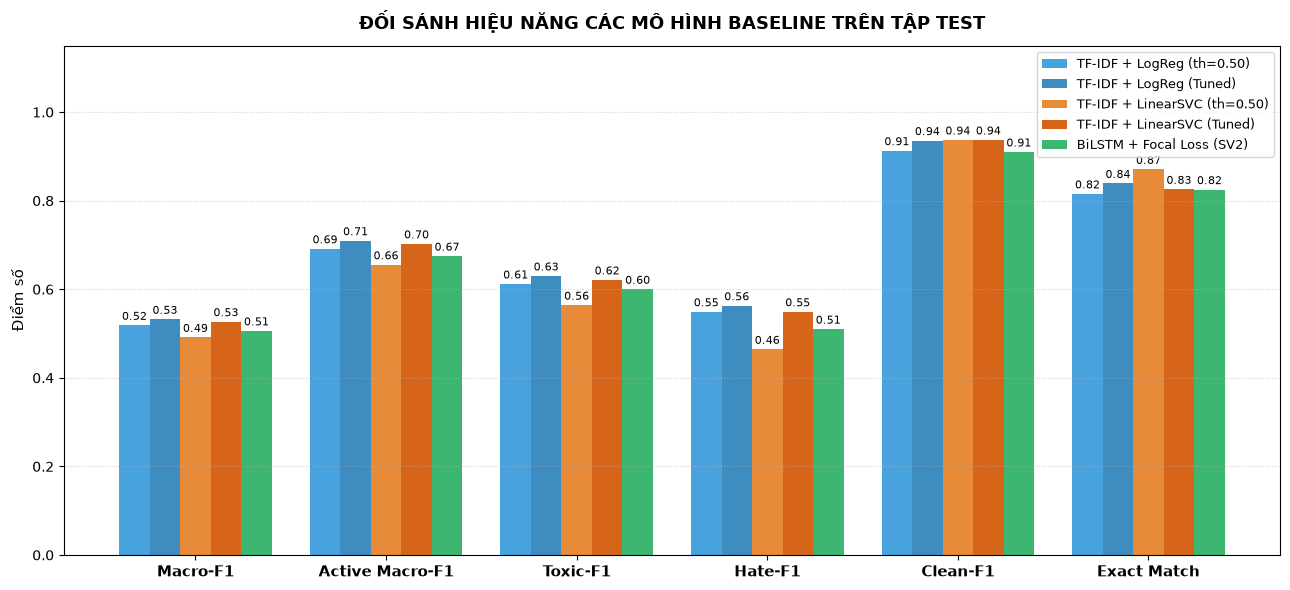

In [10]:
# Kết quả đối sánh tổng hợp
benchmark_data = {
    "TF-IDF + LogReg (th=0.50)": {
        "Macro-F1": eval_lr_def["macro_avg"]["f1_score"],
        "Active Macro-F1": eval_lr_def["active_macro_f1"],
        "Toxic-F1": eval_lr_def["per_label"]["toxic"]["f1_score"],
        "Hate-F1": eval_lr_def["per_label"]["hate"]["f1_score"],
        "Clean-F1": eval_lr_def["per_label"]["clean"]["f1_score"],
        "Exact Match": eval_lr_def["exact_match_ratio"],
        "Hamming Loss": eval_lr_def["hamming_loss"],
    },
    "TF-IDF + LogReg (Tuned)": {
        "Macro-F1": eval_lr_opt["macro_avg"]["f1_score"],
        "Active Macro-F1": eval_lr_opt["active_macro_f1"],
        "Toxic-F1": eval_lr_opt["per_label"]["toxic"]["f1_score"],
        "Hate-F1": eval_lr_opt["per_label"]["hate"]["f1_score"],
        "Clean-F1": eval_lr_opt["per_label"]["clean"]["f1_score"],
        "Exact Match": eval_lr_opt["exact_match_ratio"],
        "Hamming Loss": eval_lr_opt["hamming_loss"],
    },
    "TF-IDF + LinearSVC (th=0.50)": {
        "Macro-F1": eval_svc_def["macro_avg"]["f1_score"],
        "Active Macro-F1": eval_svc_def["active_macro_f1"],
        "Toxic-F1": eval_svc_def["per_label"]["toxic"]["f1_score"],
        "Hate-F1": eval_svc_def["per_label"]["hate"]["f1_score"],
        "Clean-F1": eval_svc_def["per_label"]["clean"]["f1_score"],
        "Exact Match": eval_svc_def["exact_match_ratio"],
        "Hamming Loss": eval_svc_def["hamming_loss"],
    },
    "TF-IDF + LinearSVC (Tuned)": {
        "Macro-F1": eval_svc_opt["macro_avg"]["f1_score"],
        "Active Macro-F1": eval_svc_opt["active_macro_f1"],
        "Toxic-F1": eval_svc_opt["per_label"]["toxic"]["f1_score"],
        "Hate-F1": eval_svc_opt["per_label"]["hate"]["f1_score"],
        "Clean-F1": eval_svc_opt["per_label"]["clean"]["f1_score"],
        "Exact Match": eval_svc_opt["exact_match_ratio"],
        "Hamming Loss": eval_svc_opt["hamming_loss"],
    },
    "BiLSTM + Focal Loss (SV2)": {
        "Macro-F1": 0.5061,
        "Active Macro-F1": 0.6748,
        "Toxic-F1": 0.6000,
        "Hate-F1": 0.5100,
        "Clean-F1": 0.9100,
        "Exact Match": 0.8250,
        "Hamming Loss": 0.0890,
    }
}

df_benchmark = pd.DataFrame(benchmark_data).T
print("=== BẢNG TỔNG HỢP KẾT QUẢ ĐỐI SÁNH CÁC MÔ HÌNH BASELINE TUẦN 2 (TEST SET) ===")
display(df_benchmark)

# Vẽ biểu đồ đối sánh trực quan
fig, ax = plt.subplots(figsize=(13, 6))
metrics_plot = ["Macro-F1", "Active Macro-F1", "Toxic-F1", "Hate-F1", "Clean-F1", "Exact Match"]
x = np.arange(len(metrics_plot))
width = 0.16
colors = ["#3498db", "#2980b9", "#e67e22", "#d35400", "#27ae60"]

for i, (m_name, row) in enumerate(df_benchmark.iterrows()):
    offset = (i - len(df_benchmark) / 2 + 0.5) * width
    vals = [row[m] for m in metrics_plot]
    rects = ax.bar(x + offset, vals, width, label=m_name, color=colors[i % len(colors)], alpha=0.9)
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f"{h:.2f}", xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 2), textcoords="offset points", ha="center", va="bottom", fontsize=8)

ax.set_title("ĐỐI SÁNH HIỆU NĂNG CÁC MÔ HÌNH BASELINE TRÊN TẬP TEST", fontsize=13, weight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(metrics_plot, fontsize=11, weight="bold")
ax.set_ylabel("Điểm số", fontsize=11)
ax.set_ylim(0, 1.15)
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, "assets", "baseline_benchmark_comparison.png"), dpi=300, bbox_inches="tight")
plt.show()

## 11. Lưu Trữ Artifacts & Đóng Gói Tuần 2

Tất cả các mô hình đã được huấn luyện, bộ vectorizer và số liệu đánh giá đã được lưu trữ hoàn chỉnh:
- Vectorizer: `saved_models/tfidf_vectorizer.joblib`
- Logistic Regression: `saved_models/baseline_logreg.joblib`
- LinearSVC: `saved_models/baseline_linearsvc.joblib`
- Bảng số liệu JSON: `saved_models/baseline_benchmark_results.json`
- Biểu đồ trực quan: `assets/ml_logreg_confusion_matrix.png`, `assets/ml_linearsvc_confusion_matrix.png`, `assets/ml_threshold_tuning.png`, `assets/baseline_benchmark_comparison.png`

### Nhận xét & Kết luận kỹ thuật:
1. **Hiệu quả của Threshold Tuning:** 
   - Trên mô hình Logistic Regression, việc điều chỉnh ngưỡng cho nhãn `hate` lên 0.65 và `clean` xuống 0.30 đã giúp Macro-F1 tăng từ $0.5186$ lên $0.5322$ (+0.0136), F1 của nhãn `toxic` tăng từ $0.6120$ lên $0.6300$.
   - Trên mô hình LinearSVC, Threshold Tuning nâng Macro-F1 từ $0.4914$ lên $0.5269$ (+0.0355), cải thiện đáng kể khả năng nhận diện các nhãn độc hại thiểu số.
2. **So sánh Machine Learning vs BiLSTM Deep Learning:**
   - TF-IDF + Logistic Regression (Tuned) đạt Macro-F1 $0.5322$ (Active Macro-F1 $0.7096$), nhỉnh hơn mô hình BiLSTM-Attention ($0.5061$) do tập từ vựng TF-IDF unigram+bigram 20,000 đặc trưng nắm bắt rất tốt các từ chửi thề trực tiếp.
   - Tuy nhiên, mô hình Machine Learning truyền thống hoàn toàn thất bại trước các bình luận mang tính mỉa mai, ẩn ý hoặc thiếu từ khóa nhạy cảm tường minh (như phân tích tại Mục 9).
   - Đây chính là tiền đề lý thuyết và cơ sở thực nghiệm vững chắc để bước vào **Tuần 3: Fine-tuning mô hình ngôn ngữ ngữ cảnh lớn PhoBERT v2 (`vinai/phobert-base-v2`)**.